# Demo thu thập & làm sạch dữ liệu từng bước – Nhóm 5 PTDL

Notebook này **chỉ đọc** dữ liệu đã có trong `data/` (không gửi request, không sửa file nào). Mỗi phần đi theo mẫu:

> **Vấn đề → dữ liệu TRƯỚC → xử lý → dữ liệu SAU → code thật nằm ở đâu**

Cách chạy: mở notebook này **từ thư mục `PTDL_3`** (cùng chỗ với `run_pipeline.py`), rồi chạy lần lượt từng ô (Shift + Enter).

| Phần | Nội dung |
|---|---|
| A | Thu thập: dữ liệu gốc trông như thế nào |
| B | Luồng 1 – Số liệu tài chính (`crawler/financials.py`) |
| C | Luồng 2 – Giá cổ phiếu (`crawler/prices.py`) |
| D | Luồng 3 – Sự kiện phi tài chính (`crawler/events.py`) |
| E | Ghép bảng & kiểm tra chất lượng (`crawler/build.py`) |
| F | Tóm tắt những gì cần nhớ |

In [1]:
import json, glob, sys, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "crawler").exists() and (ROOT.parent / "crawler").exists():
    ROOT = ROOT.parent
assert (ROOT / "crawler").exists(), "Hãy mở notebook từ thư mục PTDL_3 (thư mục có crawler/ và data/)"
sys.path.insert(0, str(ROOT))
from crawler import config, events          # dùng lại đúng code thật của pipeline
from crawler.build import RANGES

RAW, OUT = ROOT / "data" / "raw", ROOT / "data" / "output"
INTERIM, MANUAL = ROOT / "data" / "interim", ROOT / "data" / "manual"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)

def doc_json(pattern):
    # Đọc 1 file JSON gốc trong data/raw (khớp mẫu tên file)
    files = sorted(glob.glob(str(RAW / pattern)))
    assert files, f"Không thấy file {pattern}"
    return json.load(open(files[0], encoding="utf-8"))

print("Thư mục dự án:", ROOT)

Thư mục dự án: c:\Users\HAN NGUYEN\OneDrive - VLG\Documents\Code\PTDL_3


---
## A. Thu thập – dữ liệu gốc trông như thế nào?

Mọi phản hồi tải về được lưu **nguyên văn** trong `data/raw/` (cache). Nhờ vậy: chạy lại không phải tải lại, và khi thấy số lạ có thể mở file gốc ra đối chiếu.
Code: `crawler/http_client.py` (nghỉ 0,8 s giữa các request, tự thử lại khi lỗi 429/5xx, lưu cache).

In [2]:
for d in sorted(p for p in RAW.iterdir() if p.is_dir()):
    print(f"{d.name:28s} {len(list(d.iterdir())):4d} file")

cafef_events                  207 file
vietstock_news                696 file
vnd_events                      8 file
vnd_financial_statements       16 file
vnd_news                       11 file
vnd_ratios                      8 file
vnd_stock_prices               16 file


### A1. BCTC quý từ API VNDirect (JSON)
Request gửi đi có dạng `.../v4/financial_statements?q=code:VCB~reportType:QUARTER~modelType:101,102~fiscalDate:...`
(101 = bảng cân đối kế toán, 102 = kết quả kinh doanh). Code: `financials.py` → `fetch_statements`.

In [3]:
dates = [d.strftime("%Y-%m-%d") for d in pd.date_range(config.FIN_FROM, config.FIN_TO, freq="QE")]
q = f"code:VCB~reportType:QUARTER~modelType:101,102~fiscalDate:{','.join(dates)}"
print("Request:", config.VND_API + "/financial_statements?q=" + q[:110] + "...")

d = doc_json("vnd_financial_statements/VCB_QUARTER_*.json")
print("Các khóa trong phản hồi:", list(d.keys()), "| tổng bản ghi:", d["totalElements"], "| số trang:", d["totalPages"])
bctc_vcb = pd.DataFrame(d["data"])
print("Kích thước:", bctc_vcb.shape, "| số chỉ tiêu:", bctc_vcb["itemCode"].nunique(), "| số quý:", bctc_vcb["fiscalDate"].nunique())
bctc_vcb.head()

Request: https://api-finfo.vndirect.com.vn/v4/financial_statements?q=code:VCB~reportType:QUARTER~modelType:101,102~fiscalDate:2020-12-31,2021-03-31,2021-06-30,2021-09-30,2021-12-3...
Các khóa trong phản hồi: ['data', 'currentPage', 'size', 'totalElements', 'totalPages'] | tổng bản ghi: 2625 | số trang: 1
Kích thước: (2625, 8) | số chỉ tiêu: 125 | số quý: 21


,code,itemCode,reportType,modelType,numericValue,fiscalDate,createdDate,modifiedDate
0,VCB,411500.0,QUARTER,101.0,3.906378e+12,2021-03-31,2021-05-04 00:00:00,2024-02-21 00:00:00
1,VCB,412420.0,QUARTER,101.0,7.485740e+11,2021-03-31,2021-05-04 00:00:00,2024-02-21 00:00:00
2,VCB,412440.0,QUARTER,101.0,1.587823e+12,2021-03-31,2021-05-04 00:00:00,2024-02-21 00:00:00
3,VCB,412450.0,QUARTER,101.0,-7.500000e+10,2021-03-31,2021-05-04 00:00:00,2024-02-21 00:00:00
4,VCB,600148.0,QUARTER,101.0,0.000000e+00,2021-03-31,2021-05-04 00:00:00,2024-02-21 00:00:00


**Nhận xét:** dữ liệu ở dạng **dài** – mỗi dòng là *1 chỉ tiêu của 1 quý*, tên chỉ tiêu là **mã số** (`itemCode`), tiền tính bằng **VND**. Chưa phân tích được ngay → phần B xử lý.

### A2. Giá cổ phiếu theo ngày (JSON)
Code: `prices.py` → `fetch_daily`. Chú ý có 2 loại giá: `close` (giá gốc trên bảng điện) và `adClose` (giá **đã điều chỉnh**).

In [4]:
gia_acb_goc = pd.DataFrame(doc_json("vnd_stock_prices/ACB_2020-12-01_2026-05-15_*.json")["data"])
print("Kích thước:", gia_acb_goc.shape)
gia_acb_goc[["code", "date", "close", "adClose", "open", "adOpen", "nmVolume"]].head()

Kích thước: (1352, 25)


,code,date,close,adClose,open,adOpen,nmVolume
0,ACB,2026-05-15,23.30,20.075,22.8,19.644,21591900.0
1,ACB,2026-05-14,22.80,19.644,22.5,19.386,16144400.0
2,ACB,2026-05-13,22.50,19.386,22.7,19.558,21238100.0
3,ACB,2026-05-12,22.70,19.558,22.8,19.644,10943200.0
4,ACB,2026-05-11,22.75,19.601,23.0,19.817,12866600.0


### A3. Tin tức CafeF (HTML)
CafeF trả về **HTML**, không phải JSON. Code: `events.py` → `fetch_cafef` (lật từng trang) và `_parse_cafef_page` (dùng BeautifulSoup bóc ngày, tiêu đề, link).

In [5]:
f = sorted(glob.glob(str(RAW / "cafef_events" / "VCB_p1_*.html")))[0]
html = open(f, encoding="utf-8").read()
i = html.find("timeTitle")
print("----- HTML GỐC (một đoạn) -----")
print(html[max(0, i - 120): i + 420])

----- HTML GỐC (một đoạn) -----
e-type: none;border-bottom: 1px solid #D4E0E0;line-height:30px;background:none;">

                        <span class="timeTitle">23/09/2026 17:53</span>

                        <img style="padding:0 3px 3px 7px;" alt="" src="https://cafefnew.mediacdn.vn/static/images/red_bull.gif">

                        <a class='docnhanhTitle' href="/du-lieu/VCB-2982639/vcb-quyet-dinh-ve-viec-thay-doi-dia-chi-tru-so-cac-chi-nhanh-va-cac-pgd.chn?utm_source=du-lieu.chn" title="VCB: Quyết định về việc thay đổi địa chỉ trụ sở các Chi nhánh và các P


In [6]:
print("----- SAU KHI BÓC BẰNG BeautifulSoup -----")
pd.DataFrame(events._parse_cafef_page(html)).head()

----- SAU KHI BÓC BẰNG BeautifulSoup -----


,ngay_cong_bo,tieu_de,nguon
0,2026-09-23 17:53:00,VCB: Quyết định về việc thay đổi địa chỉ trụ sở các Chi nhánh và các PGD,https://cafef.vn/du-lieu/VCB-2982639/vcb-quyet-dinh-ve-viec-thay-doi-dia-chi-tru-so-ca...
1,2026-09-16 17:28:00,VCB: Quyết định về việc thay đổi địa điểm trụ sở Chi nhánh Phú Mỹ và Chi nhánh Gia Định,https://cafef.vn/du-lieu/VCB-2977700/vcb-quyet-dinh-ve-viec-thay-doi-dia-diem-tru-so-c...
2,2026-09-16 17:26:00,VCB: HĐQT thông qua giao dịch giữa VCB và VCBNeo,https://cafef.vn/du-lieu/VCB-2977694/vcb-hdqt-thong-qua-giao-dich-giua-vcb-va-vcbneo.chn
3,2026-09-07 17:14:00,VCB: Thông báo thay đổi địa chỉ trụ sở 04 Chi nhánh và 15 PGD ở Quảng Ninh,https://cafef.vn/du-lieu/VCB-2971152/vcb-thong-bao-thay-doi-dia-chi-tru-so-04-chi-nhan...
4,2026-08-25 00:00:00,VCB: Nghị quyết HĐQT phê duyệt chủ trương thay đổi địa điểm trụ sở chi nhánh VCB Gia Định,https://cafef.vn/du-lieu/VCB-2963120/vcb-nghi-quyet-hdqt-phe-duyet-chu-truong-thay-doi...


### A4. Sự kiện quyền VNDirect (JSON) – nguồn chắc chắn cho "tăng vốn"
Code: `events.py` → `fetch_vnd_capital_events`. Chỉ giữ các loại `STOCKDIV`, `KINDDIV`, `ISSUE`, `schedIssue` (`config.VND_CAPITAL_EVENT_TYPES`).

In [7]:
ev_vpb = pd.DataFrame(doc_json("vnd_events/VPB_events_*.json")["data"])
ev_vpb[["code", "type", "typeDesc", "disclosureDate", "note"]].head(6)

,code,type,typeDesc,disclosureDate,note
0,VPB,schedDiv,Dự kiến cổ tức,2021-09-27,"Dự kiến trả cổ tức bằng cổ phiếu năm , tỷ lệ 100:62.15"
1,VPB,schedIssue,Dự kiến phát hành,2021-09-27,"Dự kiến phát hành 440,800,688cp cho CĐHH"
2,VPB,STOCKDIV,Cổ tức bằng cổ phiếu,2021-09-30,"Trả cổ tức năm 2021, Tỷ lệ 100:62.15"
3,VPB,KINDDIV,Cổ phiếu thưởng,2021-09-30,Tỷ lệ 100:17.85
4,VPB,LISTED,GD bổ sung,2021-10-19,"Số lượng 5,250,000 cp"
5,VPB,LISTED,GD bổ sung,2021-10-19,"Số lượng 2,500,000 cp"


---
## B. Luồng 1 – Số liệu tài chính (`crawler/financials.py` → `bang1_tai_chinh_quy.csv`)

### B1. Chọn đúng chỉ tiêu
API trả 125 chỉ tiêu, nhóm chỉ cần 11. Bảng "mã → tên cột" nằm ở `config.py` (`BS_ITEMS`, `IS_ITEMS`).

In [8]:
chon = pd.DataFrame([{"modelType": 101, "itemCode": k, "ten_cot": v} for k, v in config.BS_ITEMS.items()] +
                    [{"modelType": 102, "itemCode": k, "ten_cot": v} for k, v in config.IS_ITEMS.items()])
print(len(chon), "chỉ tiêu được chọn /", bctc_vcb["itemCode"].nunique(), "chỉ tiêu API trả về")
chon

17 chỉ tiêu được chọn / 125 chỉ tiêu API trả về


,modelType,itemCode,ten_cot
0,101,12700,tong_tai_san
1,101,14000,von_chu_so_huu
2,101,412100,tong_du_no
3,101,412200,du_phong_cho_vay
4,101,413300,tien_gui_khach_hang
5,101,411200,tien_gui_nhnn
6,101,411400,tien_gui_cho_vay_tctd
7,101,411500,chung_khoan_kinh_doanh
8,101,412300,chung_khoan_dau_tu
9,101,700491,mua_no


### B2. Kiểm tra bản trùng (BCTC sửa / kiểm toán lại)
Code phòng sẵn: sắp theo `modifiedDate`, giữ bản cuối (`fetch_statements`). **Thực tế có bao nhiêu dòng trùng?**

In [9]:
tong, trung = 0, 0
for f in sorted(glob.glob(str(RAW / "vnd_financial_statements" / "*_QUARTER_*.json"))):
    x = pd.DataFrame(json.load(open(f, encoding="utf-8"))["data"])
    tong += len(x)
    trung += x.duplicated(["code", "fiscalDate", "modelType", "itemCode"]).sum()
print(f"Tổng {tong:,} dòng BCTC quý của 8 ngân hàng – số dòng trùng: {trung}")

Tổng 21,000 dòng BCTC quý của 8 ngân hàng – số dòng trùng: 0


→ **0 dòng trùng.** Bước này là *phòng ngừa*, không phải lỗi đã gặp. Nếu thầy hỏi "xóa bao nhiêu dòng trùng?" thì trả lời đúng là 0.

### B3. Xoay bảng dài → rộng (`_pivot_items`, dùng `pivot_table`)

In [10]:
b = bctc_vcb.copy()
b["itemCode"] = b["itemCode"].astype(int)
b["modelType"] = b["modelType"].astype(int)
ma_can = {(r.modelType, r.itemCode): r.ten_cot for r in chon.itertuples()}
b = b[[(m, i) in ma_can for m, i in zip(b["modelType"], b["itemCode"])]].copy()
b["ten_cot"] = [ma_can[(m, i)] for m, i in zip(b["modelType"], b["itemCode"])]

print("TRƯỚC (dạng dài) – VCB Q1/2024, mỗi dòng 1 chỉ tiêu:")
display(b[b["fiscalDate"] == "2024-03-31"][["code", "fiscalDate", "itemCode", "ten_cot", "numericValue"]])

TRƯỚC (dạng dài) – VCB Q1/2024, mỗi dòng 1 chỉ tiêu:


,code,fiscalDate,itemCode,ten_cot,numericValue
802,VCB,2024-03-31,700491,mua_no,0.000000e+00
896,VCB,2024-03-31,413300,tien_gui_khach_hang,1.347326e+15
899,VCB,2024-03-31,411500,chung_khoan_kinh_doanh,2.936121e+12
900,VCB,2024-03-31,14000,von_chu_so_huu,1.736141e+14
984,VCB,2024-03-31,23800,loi_nhuan_truoc_thue,1.071824e+13
986,VCB,2024-03-31,23000,lnst_cong_ty_me,8.579996e+12
987,VCB,2024-03-31,422900,chi_phi_du_phong,1.508210e+12
991,VCB,2024-03-31,412100,tong_du_no,1.266478e+15
992,VCB,2024-03-31,411200,tien_gui_nhnn,3.783662e+13
1512,VCB,2024-03-31,421701,tong_thu_nhap_hoat_dong,1.728040e+13


In [11]:
rong = b.pivot_table(index=["code", "fiscalDate"], columns="ten_cot", values="numericValue", aggfunc="last").reset_index()
print("SAU (dạng rộng): mỗi dòng 1 quý, mỗi chỉ tiêu 1 cột →", rong.shape)
rong.tail(3)

SAU (dạng rộng): mỗi dòng 1 quý, mỗi chỉ tiêu 1 cột → (21, 19)


ten_cot,code,fiscalDate,chi_phi_du_phong,chi_phi_hoat_dong,chung_khoan_dau_tu,chung_khoan_kinh_doanh,du_phong_cho_vay,lnst_cong_ty_me,loi_nhuan_sau_thue,loi_nhuan_truoc_thue,mua_no,thu_nhap_lai_thuan,tien_gui_cho_vay_tctd,tien_gui_khach_hang,tien_gui_nhnn,tong_du_no,tong_tai_san,tong_thu_nhap_hoat_dong,von_chu_so_huu
18,VCB,2025-06-30,8.095900e+11,6.024732e+12,1.624344e+14,7.992828e+12,-3.330700e+13,8.831885e+12,8.837371e+12,1.103392e+13,0.0,1.416019e+13,4.325415e+14,1.586683e+15,3.768600e+13,1.555769e+15,2.217637e+15,1.786824e+13,2.137494e+14
19,VCB,2025-09-30,7.755870e+11,6.037436e+12,1.656348e+14,5.251130e+12,-3.400853e+13,9.020499e+12,9.025553e+12,1.123910e+13,0.0,1.465724e+13,4.978587e+14,1.611967e+15,5.657716e+13,1.629943e+15,2.378186e+15,1.805213e+13,2.227915e+14
20,VCB,2025-12-31,8.546530e+11,7.528194e+12,1.621042e+14,1.183258e+13,-2.497568e+13,8.629050e+12,8.633290e+12,1.088668e+13,0.0,1.626682e+13,5.224744e+14,1.672535e+15,3.744550e+13,1.673526e+15,2.442279e+15,1.926953e+13,2.245587e+14


### B4. Đổi đơn vị
Tiền: VND ÷ 10⁹ → **tỷ đồng**. Tỷ lệ NPL, CAR: số thập phân × 100 → **%**.

In [12]:
r = rong[rong["fiscalDate"] == "2024-03-31"].iloc[0]
print(f"Tổng tài sản VCB Q1/2024 gốc : {r.tong_tai_san:,.0f} VND")
print(f"Sau khi chia 1e9             : {r.tong_tai_san / 1e9:,.1f} tỷ đồng")

ratios_vcb = pd.DataFrame(doc_json("vnd_ratios/VCB_*.json")["data"])
npl = ratios_vcb[(ratios_vcb["ratioCode"] == "BAD_LOANS_RATIO_AQ") & (ratios_vcb["reportDate"].str[:10] == "2024-03-31")]["value"].iloc[0]
print(f"NPL gốc: {npl:.6f}  →  × 100 = {npl * 100:.2f}%")

Tổng tài sản VCB Q1/2024 gốc : 1,773,713,584,000,000 VND
Sau khi chia 1e9             : 1,773,713.6 tỷ đồng
NPL gốc: 0.012207  →  × 100 = 1.22%


### B5. Tự tính ROA – làm tay một lần để hiểu công thức (`compute_indicators`)
ROA (năm hóa) = LNST quý × 4 / bình quân(tổng tài sản đầu quý, cuối quý) × 100.
Đầu quý Q1/2024 = cuối Q4/2023 → đó là lý do pipeline lấy thêm dữ liệu Q4/2020 (để có "đầu kỳ" cho Q1/2021).

In [13]:
q4_23 = rong[rong["fiscalDate"] == "2023-12-31"].iloc[0]
lnst = r.loi_nhuan_sau_thue / 1e9
ts_bq = (q4_23.tong_tai_san + r.tong_tai_san) / 2 / 1e9
roa_tay = lnst * 4 / ts_bq * 100

bang1 = pd.read_csv(OUT / "bang1_tai_chinh_quy.csv")
roa_pipe = bang1.query("ma_nh == 'VCB' and nam == 2024 and quy == 'Q1'")["roa"].iloc[0]
print(f"LNST quý = {lnst:,.1f} tỷ | TS bình quân = ({q4_23.tong_tai_san/1e9:,.1f} + {r.tong_tai_san/1e9:,.1f}) / 2 = {ts_bq:,.1f} tỷ")
print(f"ROA tính tay        = {lnst:,.1f} × 4 / {ts_bq:,.1f} × 100 = {roa_tay:.4f}%")
print(f"ROA trong bang1.csv = {roa_pipe:.4f}%   → khớp: {abs(roa_tay - roa_pipe) < 1e-3}")

LNST quý = 8,586.0 tỷ | TS bình quân = (1,839,223.3 + 1,773,713.6) / 2 = 1,806,468.5 tỷ
ROA tính tay        = 8,586.0 × 4 / 1,806,468.5 × 100 = 1.9012%
ROA trong bang1.csv = 1.9012%   → khớp: True


### B6. CAR bị thiếu → điền tiếp số đã công bố gần nhất (forward-fill) + đánh dấu
**Vấn đề:** nguồn chỉ có CAR cuối năm.

In [14]:
print("Các số CAR VCB có trong nguồn (chỉ 5 mốc cuối năm):")
display(ratios_vcb[ratios_vcb["ratioCode"] == "BANK_CAR_AQ"][["reportDate", "value"]])

Các số CAR VCB có trong nguồn (chỉ 5 mốc cuối năm):


,reportDate,value
4,2020-12-31,0.0960
23,2021-12-31,0.0931
47,2022-12-31,0.0995
66,2023-12-31,0.1139
87,2024-12-31,0.1216


**Vì sao điền tiếp (ffill) mà không nội suy?** Ví dụ đồ chơi dưới đây: nội suy cho Q1/2022 dùng cả số cuối 2022 – lúc đó chưa ai biết số này → "nhìn trước tương lai".

In [15]:
vd = pd.DataFrame({"quy": ["Q4/2021", "Q1/2022", "Q2/2022", "Q3/2022", "Q4/2022"],
                   "car_nguon_co": [8.97, np.nan, np.nan, np.nan, 8.00]})
vd["dien_tiep_ffill (DÙNG)"] = vd["car_nguon_co"].ffill()
vd["noi_suy (KHÔNG dùng)"] = vd["car_nguon_co"].interpolate()
vd

,quy,car_nguon_co,dien_tiep_ffill (DÙNG),noi_suy (KHÔNG dùng)
0,Q4/2021,8.97,8.97,8.9700
1,Q1/2022,NaN,8.97,8.7275
2,Q2/2022,NaN,8.97,8.4850
3,Q3/2022,NaN,8.97,8.2425
4,Q4/2022,8.00,8.00,8.0000


In [16]:
print("Kết quả thật trong bang1 – BID:")
display(bang1[bang1["ma_nh"] == "BID"][["quy", "nam", "car", "car_nguon"]].head(9))
print(bang1["car_nguon"].value_counts())

Kết quả thật trong bang1 – BID:


,quy,nam,car,car_nguon
20,Q1,2021,8.60,dien_tiep_ky_truoc
21,Q2,2021,8.60,dien_tiep_ky_truoc
22,Q3,2021,8.60,dien_tiep_ky_truoc
23,Q4,2021,8.97,cong_bo
24,Q1,2022,8.97,dien_tiep_ky_truoc
25,Q2,2022,8.97,dien_tiep_ky_truoc
26,Q3,2022,8.97,dien_tiep_ky_truoc
27,Q4,2022,8.92,tra_thu_cong
28,Q1,2023,8.92,dien_tiep_ky_truoc


car_nguon
dien_tiep_ky_truoc    128
cong_bo                26
tra_thu_cong            6
Name: count, dtype: int64


**Phát hiện khi kiểm tra lại – và đã sửa.** Số CAR VNDirect có cho BID và CTG là **8,00 đúng ba năm 2022–2024** (đúng ngưỡng tối thiểu), trong khi các ngân hàng khác đều là số lẻ.
VietinBank chỉ ghi "Tuân thủ" trong báo cáo thường niên; BIDV thì công bố số khác (ví dụ 9,18% hợp nhất cuối 2023).
Nhóm tra thủ công, ghi vào `data/manual/car_tra_thu_cong.csv` (mỗi dòng có link nguồn và lý do), và pipeline thay số **trước** bước điền tiếp (hàm `_apply_car_manual` trong `financials.py`) → `car_nguon = tra_thu_cong`.

In [17]:
# TRƯỚC: số CAR gốc trong file VNDirect | SAU: dòng Q4 trong bang1 | kèm loại CAR và link nguồn tra thủ công
rows = []
for ma in ["BID", "CTG"]:
    r = pd.DataFrame(doc_json(f"vnd_ratios/{ma}_*.json")["data"])
    r = r[r["ratioCode"] == "BANK_CAR_AQ"]
    rows += [(ma, int(d[:4]), round(v * 100, 2)) for d, v in zip(r["reportDate"], r["value"])]
truoc = pd.DataFrame(rows, columns=["ma_nh", "nam", "car_vndirect"])
car_tay = pd.read_csv(MANUAL / "car_tra_thu_cong.csv", encoding="utf-8-sig")
sau = bang1[(bang1["quy"] == "Q4") & bang1["ma_nh"].isin(["BID", "CTG"])][["ma_nh", "nam", "car", "car_nguon"]]
(truoc.merge(sau, on=["ma_nh", "nam"], how="right")
      .merge(car_tay[["ma_nh", "nam", "loai_car", "nguon"]], on=["ma_nh", "nam"], how="left"))

,ma_nh,nam,car_vndirect,car,car_nguon,loai_car,nguon
0,BID,2021,8.97,8.97,cong_bo,NaN,NaN
1,BID,2022,8.00,8.92,tra_thu_cong,rieng_le,https://bidv.com.vn/bidv_en/tin-tuc/thong-tin-bao-chi/bidv-to-chuc-dai-hoi-dong-co-don...
2,BID,2023,8.00,9.18,tra_thu_cong,hop_nhat,https://bidv.com.vn/wps/wcm/connect/401164ee-9c00-48df-b47d-2d9ffbeeacf0/Vi_BaocaoCBTT...
3,BID,2024,8.00,9.03,tra_thu_cong,hop_nhat,https://bidv.com.vn/bidv_en/tin-tuc/thong-tin-bao-chi/bidv-to-chuc-dai-hoi-dong-co-don...
4,BID,2025,NaN,9.03,dien_tiep_ky_truoc,NaN,NaN
5,CTG,2021,9.14,9.14,cong_bo,NaN,NaN
6,CTG,2022,8.00,8.90,tra_thu_cong,khong_ro,https://www.kbsec.com.vn/pic/Service/KBSV_Baocaocapnhat_CTG_2Q2023.pdf
7,CTG,2023,8.00,9.30,tra_thu_cong,khong_ro,https://mbs.com.vn/files/uploads/2025/10/CTG_UPDATE_20251008.pdf
8,CTG,2024,8.00,9.60,tra_thu_cong,khong_ro,https://mbs.com.vn/files/uploads/2025/10/CTG_UPDATE_20251008.pdf
9,CTG,2025,NaN,9.60,dien_tiep_ky_truoc,NaN,NaN


In [18]:
print("CAR thật (cong_bo + tra_thu_cong) theo năm – không còn số 8,00 nào:")
bang1[bang1["car_nguon"].isin(["cong_bo", "tra_thu_cong"])].pivot_table(index="ma_nh", columns="nam", values="car")

CAR thật (cong_bo + tra_thu_cong) theo năm – không còn số 8,00 nào:


nam,2021,2022,2023,2024
ma_nh,,,,
ACB,11.23,12.80,12.50,11.80
BID,8.97,8.92,9.18,9.03
CTG,9.14,8.90,9.30,9.60
MBB,10.02,11.53,10.75,11.80
STB,9.93,9.49,9.11,10.14
TCB,15.00,15.20,14.40,15.30
VCB,9.31,9.95,11.39,12.16
VPB,14.30,14.90,17.10,15.50


### B7. Kiểm tra chéo: tổng LNST 4 quý có khớp BCTC năm không?
Nếu số quý bị cộng dồn (lũy kế) nhầm, tổng 4 quý sẽ lệch xa số năm. Code: `build.py` → `validation_report`, mục 3.

In [19]:
rows = []
for f in sorted(glob.glob(str(RAW / "vnd_financial_statements" / "*_ANNUAL_*.json"))):
    x = pd.DataFrame(json.load(open(f, encoding="utf-8"))["data"])
    x = x[x["itemCode"].astype(int) == 23003]
    rows += [(c, int(fd[:4]), v / 1e9) for c, fd, v in zip(x["code"], x["fiscalDate"], x["numericValue"])]
nam = pd.DataFrame(rows, columns=["ma_nh", "nam", "lnst_bctc_nam"])
tong4q = bang1.groupby(["ma_nh", "nam"], as_index=False)["loi_nhuan_sau_thue"].sum()
ss = nam.merge(tong4q, on=["ma_nh", "nam"])
ss["lech_%"] = (ss["loi_nhuan_sau_thue"] / ss["lnst_bctc_nam"] - 1) * 100
print(f"{len(ss)} cặp ngân hàng-năm, lệch lớn nhất: {ss['lech_%'].abs().max():.2f}%")
ss.sort_values("lech_%", key=abs, ascending=False).head(5).round(2)

40 cặp ngân hàng-năm, lệch lớn nhất: 1.73%


,ma_nh,nam,lnst_bctc_nam,loi_nhuan_sau_thue,lech_%
35,VPB,2023,8494.17,8640.79,1.73
38,VPB,2021,11477.17,11650.52,1.51
10,CTG,2023,20044.62,20133.40,0.44
8,BID,2021,10841.27,10878.65,0.34
6,BID,2024,25677.12,25604.04,-0.28


---
## C. Luồng 2 – Giá cổ phiếu (`crawler/prices.py` → `bang2a_gia_ngay.csv`, `bang2b_gia_quy.csv`)

### C1. Vấn đề lớn nhất: giá "rơi" khi chia cổ tức bằng cổ phiếu
Lọc những phiên giá gốc giảm > 9% nhưng giá điều chỉnh gần như không đổi:

In [20]:
gia = pd.read_csv(OUT / "bang2a_gia_ngay.csv").sort_values(["ma_nh", "ngay"])
print(f"Số phiên: {len(gia):,} | tỷ lệ phiên có giá gốc ≠ giá điều chỉnh: {(gia['gia_dong_cua'] != gia['gia_dong_cua_dieu_chinh']).mean():.1%}")
gia["doi_gia_goc_%"] = gia.groupby("ma_nh")["gia_dong_cua"].pct_change() * 100
gia["doi_gia_dieu_chinh_%"] = gia.groupby("ma_nh")["gia_dong_cua_dieu_chinh"].pct_change() * 100
roi = gia[(gia["doi_gia_goc_%"] < -9) & ((gia["doi_gia_goc_%"] - gia["doi_gia_dieu_chinh_%"]).abs() > 5)]
roi[["ma_nh", "ngay", "gia_dong_cua", "gia_dong_cua_dieu_chinh", "doi_gia_goc_%", "doi_gia_dieu_chinh_%"]].round(2)

Số phiên: 10,851 | tỷ lệ phiên có giá gốc ≠ giá điều chỉnh: 87.5%


,ma_nh,ngay,gia_dong_cua,gia_dong_cua_dieu_chinh,doi_gia_goc_%,doi_gia_dieu_chinh_%
6908,ACB,2021-06-10,34.10,13.78,-19.67,0.42
7152,ACB,2022-06-02,25.35,12.80,-18.49,1.89
7401,ACB,2023-06-01,21.40,12.94,-15.75,0.87
7650,ACB,2024-05-31,24.65,17.74,-16.16,-0.19
7893,ACB,2025-05-23,21.60,18.61,-15.46,1.19
1623,BID,2021-12-23,34.50,23.15,-20.32,0.68
2104,BID,2023-11-28,38.85,29.38,-9.65,1.82
2371,BID,2024-12-23,38.60,35.32,-16.90,0.56
2861,CTG,2021-07-07,39.05,23.04,-19.48,3.92
3463,CTG,2023-11-30,26.30,17.76,-10.54,-0.04


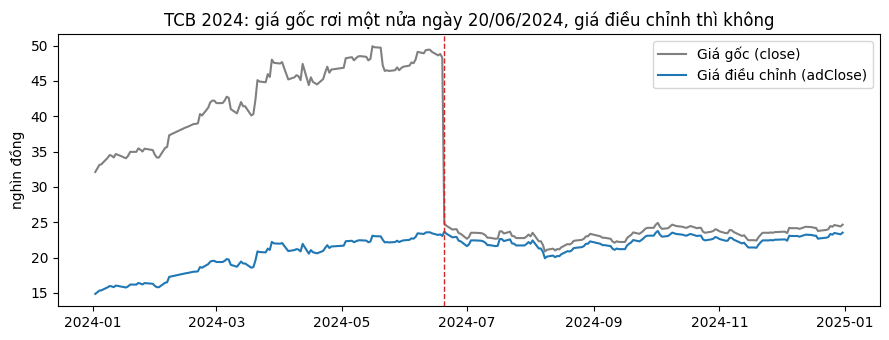

In [21]:
# Vẽ TCB năm 2024 để thấy tận mắt (cần matplotlib)
try:
    import matplotlib.pyplot as plt
    t = gia[(gia["ma_nh"] == "TCB") & (gia["ngay"].between("2024-01-01", "2024-12-31"))].copy()
    t["ngay"] = pd.to_datetime(t["ngay"])
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.plot(t["ngay"], t["gia_dong_cua"], label="Giá gốc (close)", color="grey")
    ax.plot(t["ngay"], t["gia_dong_cua_dieu_chinh"], label="Giá điều chỉnh (adClose)", color="tab:blue")
    ax.axvline(pd.Timestamp("2024-06-20"), ls="--", color="tab:red", lw=1)
    ax.set_title("TCB 2024: giá gốc rơi một nửa ngày 20/06/2024, giá điều chỉnh thì không")
    ax.set_ylabel("nghìn đồng"); ax.legend(); plt.tight_layout(); plt.show()
except ImportError:
    print("Chưa cài matplotlib – bỏ qua biểu đồ (pip install matplotlib)")

### C2. Ảnh hưởng tới lợi suất quý – ví dụ TCB quý 2/2024

In [22]:
q = pd.read_csv(OUT / "bang2b_gia_quy.csv")
display(q.query("ma_nh == 'TCB' and nam == 2024")[["quy", "gia_dau_quy", "gia_cuoi_quy", "ty_suat_sinh_loi_quy"]])
# Giá gốc (chưa điều chỉnh) phiên cuối mỗi quý lấy từ bảng giá ngày
t = gia[gia["ma_nh"] == "TCB"]
goc = t.groupby(pd.to_datetime(t["ngay"]).dt.to_period("Q"))["gia_dong_cua"].last()
goc_dau, goc_cuoi = goc[pd.Period("2024Q1")], goc[pd.Period("2024Q2")]
dc = q.query("ma_nh == 'TCB' and nam == 2024 and quy == 'Q2'")["ty_suat_sinh_loi_quy"].iloc[0]
print(f"Nếu dùng giá gốc      : {goc_cuoi} / {goc_dau} - 1 = {(goc_cuoi / goc_dau - 1) * 100:.1f}%   ← SAI")
print(f"Dùng giá điều chỉnh   : {dc:.2f}%   ← ĐÚNG (pipeline dùng cái này)")

,quy,gia_dau_quy,gia_cuoi_quy,gia_cuoi_quy_chua_dieu_chinh,ty_suat_sinh_loi_quy
112,Q1,14.713,21.999,47.55,49.5208
113,Q2,21.999,22.279,23.35,1.2728
114,Q3,22.279,23.090,24.20,3.6402
115,Q4,23.090,23.519,24.65,1.8579


Nếu dùng giá gốc      : 23.35 / 47.55 - 1 = -50.9%   ← SAI
Dùng giá điều chỉnh   : 1.27%   ← ĐÚNG (pipeline dùng cái này)


### C3. Tạo nhãn `xu_huong_quy_sau` – chống "nhìn trước tương lai"
**Vấn đề:** BCTC quý t chỉ được công bố *sau* cuối quý (hạn chót 45 ngày, TT96/2020). Nếu đo giá từ cuối quý thì mô hình dùng thông tin chưa ai biết.
**Cách làm:** mốc dự báo = cuối quý + 45 ngày; nhãn = giá tại mốc quý sau so với giá tại mốc quý này. Code: `prices.py` → `aggregate_quarterly` + `price_on_or_before` (`merge_asof` hướng backward).

In [23]:
gia_vcb = gia[gia["ma_nh"] == "VCB"]
def gia_tai_moc(ngay):
    # Giá đóng cửa điều chỉnh của phiên cuối cùng <= ngày mốc (mốc rơi vào ngày nghỉ thì lấy phiên trước)
    x = gia_vcb[gia_vcb["ngay"] <= ngay].tail(1)
    return x["ngay"].iloc[0], x["gia_dong_cua_dieu_chinh"].iloc[0]

moc_t = (pd.Timestamp("2024-03-31") + pd.Timedelta(days=45)).strftime("%Y-%m-%d")
moc_t1 = (pd.Timestamp("2024-06-30") + pd.Timedelta(days=45)).strftime("%Y-%m-%d")
n0, p0 = gia_tai_moc(moc_t)
n1, p1 = gia_tai_moc(moc_t1)
ls = (p1 / p0 - 1) * 100
print(f"Mốc dự báo của Q1/2024 = 31/03 + 45 ngày = {moc_t} → phiên {n0}, giá {p0}")
print(f"Mốc dự báo của Q2/2024 = 30/06 + 45 ngày = {moc_t1} → phiên {n1}, giá {p1}")
print(f"Lợi suất = {p1} / {p0} - 1 = {ls:.4f}%  →  nhãn = {int(ls > 0)} ({'tăng' if ls > 0 else 'không tăng'})")
print("Trong bang2b:")
q.query("ma_nh == 'VCB' and nam == 2024 and quy == 'Q1'")[["ty_suat_sinh_loi_quy_sau", "xu_huong_quy_sau"]]

Mốc dự báo của Q1/2024 = 31/03 + 45 ngày = 2024-05-15 → phiên 2024-05-15, giá 59.93
Mốc dự báo của Q2/2024 = 30/06 + 45 ngày = 2024-08-14 → phiên 2024-08-14, giá 57.954
Lợi suất = 57.954 / 59.93 - 1 = -3.2972%  →  nhãn = 0 (không tăng)
Trong bang2b:


,ty_suat_sinh_loi_quy_sau,xu_huong_quy_sau
132,-3.2972,0.0


**Mốc 45 ngày có an toàn không?** Kiểm tra bằng ngày VNDirect nhập BCTC lần đầu (`createdDate` trong file gốc):

In [24]:
rows = []
for f in sorted(glob.glob(str(RAW / "vnd_financial_statements" / "*_QUARTER_*.json"))):
    x = pd.DataFrame(json.load(open(f, encoding="utf-8"))["data"])
    rows.append(x.groupby(["code", "fiscalDate"], as_index=False)["createdDate"].min())
tre = pd.concat(rows)
tre = tre[tre["fiscalDate"] >= "2021-01-01"]
tre["tre_ngay"] = (pd.to_datetime(tre["createdDate"]) - pd.to_datetime(tre["fiscalDate"])).dt.days
print(f"Số ngày từ cuối quý đến khi BCTC có trên VNDirect: trung vị {tre['tre_ngay'].median():.0f}, chậm nhất {tre['tre_ngay'].max()}")
print("Số kỳ nhập SAU mốc 45 ngày:", int((tre["tre_ngay"] > 45).sum()))
print("Cân bằng nhãn:", q["xu_huong_quy_sau"].value_counts().to_dict())

Số ngày từ cuối quý đến khi BCTC có trên VNDirect: trung vị 29, chậm nhất 39
Số kỳ nhập SAU mốc 45 ngày: 0
Cân bằng nhãn: {1.0: 90, 0.0: 70}


---
## D. Luồng 3 – Sự kiện phi tài chính (`crawler/events.py` → `bang3a`, `bang3b`)

File `data/interim/tin_tho_da_phan_loai.csv` chứa **toàn bộ tin thô** kèm kết quả phân loại, cờ tin ngành và đánh dấu rà soát tay → dùng để đếm lại từng tầng lọc.

In [25]:
tin = pd.read_csv(INTERIM / "tin_tho_da_phan_loai.csv")
tin["ngay"] = pd.to_datetime(tin["ngay_cong_bo"])
print("Tổng tin thô:", len(tin))
tin["nguon_du_lieu"].str.split("/").str[0].value_counts()

Tổng tin thô: 5636


nguon_du_lieu
CafeF               5225
VNDirect-news        376
VNDirect-events       34
Bổ sung thủ công       1
Name: count, dtype: int64

### D1. Phân loại bằng từ khóa – thử hàm `classify` thật trên vài tiêu đề
Mỗi loại sự kiện có 3 nhóm mẫu trong `config.EVENT_RULES`: `any` (khớp 1 là ứng viên), `require` (phải khớp thêm), `deny` (khớp thì loại). Hàm `giai_thich` dưới đây chạy đúng logic đó nhưng in ra *lý do*.

In [26]:
def giai_thich(title):
    t = " " + title.lower() + " "
    m = events._EXCLUDE_RE.search(t)
    if m:
        return f"Loại ngay: tin thường quy (khớp «{m.group(0).strip()}»)"
    ghi_chu = []
    for cat, any_rx, req_rx, deny_rx in events._RULES:
        a = any_rx.search(t)
        if not a:
            continue
        if req_rx is not None and not req_rx.search(t):
            ghi_chu.append(f"{cat}: khớp «{a.group(0).strip()}» nhưng thiếu từ bắt buộc")
            continue
        dn = deny_rx.search(t) if deny_rx is not None else None
        if dn:
            ghi_chu.append(f"{cat}: khớp «{a.group(0).strip()}» nhưng bị chặn bởi «{dn.group(0).strip()}»")
            continue
        return "; ".join(ghi_chu + [f"→ {cat} (khớp «{a.group(0).strip()}»)"])
    return "; ".join(ghi_chu) or "Không khớp loại nào → bỏ"

vi_du = [
    "VPB: Phát hành cổ phiếu ESOP",
    "VCB: Bổ nhiệm ông Phạm Quang Dũng làm Chủ tịch HĐQT nhiệm kỳ 2018 - 2023",
    "CTG: Bổ nhiệm ông Võ Thanh Sơn giữ chức Phó TGĐ",
    "ACB: Báo cáo tài chính quý 1/2024",
    "Chứng khoán ACB tăng vốn điều lệ",
    "TCB: Thông báo UBCKNN nhận đủ hồ sơ tăng vốn",
    "Techcombank bắt tay Manulife phân phối bảo hiểm",
    "VPB: Giải tỏa ESOP 2018 đợt 3",
]
pd.DataFrame({"tieu_de": vi_du,
              "classify()": [events.classify(t) for t in vi_du],
              "vì sao": [giai_thich(t) for t in vi_du]})

,tieu_de,classify(),vì sao
0,VPB: Phát hành cổ phiếu ESOP,tang_von,→ tang_von (khớp «phát hành cổ phiếu»)
1,VCB: Bổ nhiệm ông Phạm Quang Dũng làm Chủ tịch HĐQT nhiệm kỳ 2018 - 2023,doi_lanh_dao,→ doi_lanh_dao (khớp «bổ nhiệm»)
2,CTG: Bổ nhiệm ông Võ Thanh Sơn giữ chức Phó TGĐ,None,doi_lanh_dao: khớp «bổ nhiệm» nhưng bị chặn bởi «phó tgđ»
3,ACB: Báo cáo tài chính quý 1/2024,None,Loại ngay: tin thường quy (khớp «báo cáo tài chính»)
4,Chứng khoán ACB tăng vốn điều lệ,None,tang_von: khớp «tăng vốn» nhưng bị chặn bởi «chứng khoán acb»
5,TCB: Thông báo UBCKNN nhận đủ hồ sơ tăng vốn,None,tang_von: khớp «tăng vốn» nhưng bị chặn bởi «ubcknn»
6,Techcombank bắt tay Manulife phân phối bảo hiểm,hop_tac_trung_thau,→ hop_tac_trung_thau (khớp «bắt tay»)
7,VPB: Giải tỏa ESOP 2018 đợt 3,None,tang_von: khớp «esop» nhưng bị chặn bởi «giải tỏa»


### D2. Đếm lại từng tầng của phễu lọc

In [27]:
td = tin["tieu_de"].fillna("")
la_vnd_event = tin["nguon_du_lieu"] == "VNDirect-events"
thuong_quy = td.map(lambda s: bool(events._EXCLUDE_RE.search(" " + s.lower() + " "))) & ~la_vnd_event
tu_dong = td.map(events.classify)
tu_dong[la_vnd_event] = "tang_von"                                  # sự kiện quyền VNDirect gán thẳng
sau_tay = tin["loai_su_kien"].notna()                                # loai_su_kien trong file = kết quả SAU rà soát tay
giu_tay = tin["ra_soat_tay"].isin(["sua_loai", "bo_sung"])
dung_nh = sau_tay & (~tin["tin_nganh_hoac_sai_ma"] | giu_tay)

k = tin[dung_nh].copy()
k["_norm"] = k["tieu_de"].fillna("").str.lower().str.replace(r"^[a-z]{3}:\s*", "", regex=True).str.strip()
k["_day"] = k["ngay"].dt.date
khong_trung = k.drop_duplicates(["ma_nh", "_norm", "_day"])
su_kien = pd.read_csv(OUT / "bang3a_su_kien_chi_tiet.csv")

pheu = pd.DataFrame({"tang": ["1. Tin thô (gồm 1 tin thêm tay)", "2. Không phải tin thường quy", "3. Khớp một loại sự kiện",
                              "4. Sau rà soát tay", "5. Đúng ngân hàng", "6. Bỏ tin đăng lại cùng ngày", "7. Sự kiện sau khi gộp"],
                     "so_tin": [len(tin), int((~thuong_quy).sum()), int(tu_dong.notna().sum()), int(sau_tay.sum()),
                                int(dung_nh.sum()), len(khong_trung), len(su_kien)]})
pheu["bot_di"] = -pheu["so_tin"].diff()
pheu

,tang,so_tin,bot_di
0,1. Tin thô (gồm 1 tin thêm tay),5636,NaN
1,2. Không phải tin thường quy,3841,1795.0
2,3. Khớp một loại sự kiện,391,3450.0
3,4. Sau rà soát tay,322,69.0
4,5. Đúng ngân hàng,310,12.0
5,6. Bỏ tin đăng lại cùng ngày,290,20.0
6,7. Sự kiện sau khi gộp,121,169.0


In [28]:
print("Rà soát tay:", tin["ra_soat_tay"].value_counts().to_dict())
print("Trong 10 tin sửa loại, số tin trước đó CHƯA có loại:", int(tu_dong[tin["ra_soat_tay"] == "sua_loai"].isna().sum()))

Rà soát tay: {'loai_bo': 74, 'sua_loai': 10, 'bo_sung': 1}
Trong 10 tin sửa loại, số tin trước đó CHƯA có loại: 5


### D3. Rà soát tay – 3 file trong `data/manual/` (mỗi dòng có lý do)

In [29]:
for ten in ["su_kien_loai_bo.csv", "su_kien_sua_loai.csv", "su_kien_bo_sung.csv"]:
    m = pd.read_csv(MANUAL / ten, encoding="utf-8-sig")
    print(f"\n=== {ten}: {len(m)} dòng ===")
    display(m.head(4))


=== su_kien_loai_bo.csv: 63 dòng ===


,ma_nh,nguon,ly_do
0,VPB,https://tapchicongthuong.vn/ngan-hang-vpbank-nop-ho-so-dang-ky-ap-dung-phuong-phap-irb...,"Hồ sơ của chính ngân hàng theo Thông tư 14, không phải quyết định chính sách của NHNN"
1,ACB,https://cafef.vn/acb-giai-phap-so-hoa-toan-dien-cho-ho-kinh-doanh-thich-ung-giai-doan-...,"Bài PR/bình luận/phỏng vấn/giải thưởng/hội thảo, không phải quyết định hay ra mắt cụ thể"
2,MBB,https://vneconomy.vn/giai-phap-ekyc-cua-mb-gianh-giai-thuong-sao-khue-2021.htm,"Bài PR/bình luận/phỏng vấn/giải thưởng/hội thảo, không phải quyết định hay ra mắt cụ thể"
3,MBB,https://cafef.vn/mb-tien-phong-dong-hanh-cung-doanh-nghiep-chuyen-doi-so-1882303230850...,"Bài PR/bình luận/phỏng vấn/giải thưởng/hội thảo, không phải quyết định hay ra mắt cụ thể"



=== su_kien_sua_loai.csv: 7 dòng ===


,ma_nh,nguon,loai_su_kien,ly_do
0,VPB,https://cafef.vn/du-lieu/VPB-295241/vpb-nghi-quyet-hdqt-thong-qua-noi-dung-va-ky-ket-v...,tang_von,"Thỏa thuận SMBC mua cổ phần phát hành riêng lẻ (tăng vốn), công bố 3/2023"
1,VPB,https://tapchicongthuong.vn/vpbank-va-fpt-is-ky-ket-trien-khai-salesforce-crm-127467.htm,chuyen_doi_so,Triển khai nền tảng Salesforce CRM (hợp đồng triển khai công nghệ)
2,VPB,https://tapchicongthuong.vn/ngan-hang-vpbank-bat-tay-lotte-c-f-ho-tro-khach-hang--mua-...,hop_tac_trung_thau,Hợp tác với LOTTE C&F (công ty tài chính) cho dịch vụ 'mua trước trả sau' - là hợp tác...
3,CTG,https://cafef.vn/du-lieu/CTG-1778700/ctg-bo-nhiem-ong-vo-thanh-son-giu-chuc-pho-tgd-ph...,doi_lanh_dao,"Phó TGĐ phụ trách Ban điều hành = người điều hành ngân hàng (bộ lọc bỏ sót vì chữ ""Phó..."



=== su_kien_bo_sung.csv: 1 dòng ===


,ma_nh,ngay_cong_bo,loai_su_kien,tieu_de,nguon,ly_do
0,ACB,2022-02-14,chuyen_doi_so,ACB chính thức ra mắt thương hiệu ngân hàng số ACB ONE,https://acb.com.vn/ve-chung-toi/acb-chinh-thuc-ra-mat-thuong-hieu-ngan-hang-so-acb-one,Không có trong nguồn đã crawl; ngày kiểm chứng trên trang ACB


*Đã sửa (03/10/2026):* dòng VPB – Lotte ("mua trước trả sau") trong `su_kien_sua_loai.csv` trước đây chép nhầm cả **loại** (`chuyen_doi_so`) lẫn **lý do** của dòng Salesforce CRM phía trên. Giờ là `hop_tac_trung_thau` với lý do đúng (hợp tác với LOTTE C&F, cùng loại với tin nâng tầm hợp tác 07/2025) → số sự kiện từ 120 thành 121.

### D4. Tin không đúng ngân hàng (`is_off_target`)
Gắn cờ khi tiêu đề dạng `XXX: ...` mà XXX là mã khác, hoặc tin nhắc từ 3 ngân hàng trở lên (tin toàn ngành).

In [30]:
print("is_off_target('BID', 'VCB: Bổ nhiệm Tổng giám đốc')  =", events.is_off_target("BID", "VCB: Bổ nhiệm Tổng giám đốc"))
print("is_off_target('VCB', 'Vietcombank, BIDV, VietinBank đồng loạt giảm lãi suất') =",
      events.is_off_target("VCB", "Vietcombank, BIDV, VietinBank đồng loạt giảm lãi suất"))
print("\nSố tin bị gắn cờ:", int(tin["tin_nganh_hoac_sai_ma"].sum()), "– vài ví dụ:")
tin[tin["tin_nganh_hoac_sai_ma"]][["ma_nh", "ngay_cong_bo", "tieu_de"]].head(6)

is_off_target('BID', 'VCB: Bổ nhiệm Tổng giám đốc')  = True
is_off_target('VCB', 'Vietcombank, BIDV, VietinBank đồng loạt giảm lãi suất') = True

Số tin bị gắn cờ: 103 – vài ví dụ:


,ma_nh,ngay_cong_bo,tieu_de
1,ACB,2021-01-19 16:55,VOS: NHTMCP Á Châu đã bán 2.720.600 cp không còn là CĐL
2,ACB,2021-01-19 16:55,VOS: NHTMCP Á Châu báo cáo thay đổi sở hữu
64,ACB,2021-07-22 11:55,"VietinBank, MB, Techcombank có chục nghìn tỷ dư nợ ngoại bảng sau trích lập?"
77,ACB,2021-10-29 15:56,"Cổ đông LPB hụt hẫng vì ""bị đánh úp"" phiên ATC, cổ đông SHB, MSB và ACB hân hoan khi g..."
83,ACB,2022-01-12 16:50,"Dự báo lợi nhuận quý 4: MB, Techcombank và BIDV tăng mạnh, ACB, Vietcombank và VietinB..."
152,ACB,2023-01-06 15:51,"Vietcombank, VietinBank, BIDV, Techcombank, MB, VPBank, ACB và HDBank sẽ có lợi thế và..."


### D5. Gộp tin trùng (`_dedup`) – một sự kiện thật thường có nhiều tin
Quy tắc: cùng ngân hàng, cùng loại, cách nhau ≤ 3 ngày → 1 sự kiện; riêng tăng vốn: tối đa 1 lần/quý. Giữ tin **sớm nhất** làm ngày công bố.

In [31]:
vpb = tin[(tin["ma_nh"] == "VPB") & (tin["loai_su_kien"] == "tang_von") & (tin["ngay"].dt.year == 2021) & (tin["ngay"].dt.quarter == 3)]
print(f"TRƯỚC: {len(vpb)} tin thô về tăng vốn của VPB trong Q3/2021")
display(vpb[["ngay_cong_bo", "tieu_de", "nguon_du_lieu"]])
print("SAU: trong bang3a chỉ còn 1 sự kiện")
su_kien.query("ma_nh == 'VPB' and nam == 2021 and quy == 'Q3' and loai_su_kien == 'tang_von'")[["ngay_cong_bo", "mo_ta_ngan", "so_tin_gop"]]

TRƯỚC: 14 tin thô về tăng vốn của VPB trong Q3/2021


,ngay_cong_bo,tieu_de,nguon_du_lieu
4850,2021-07-15 13:28,VPB: Phiếu lấy ý kiến cổ đông về việc thông qua phương án tăng vốn điều lệ năm 2021,CafeF
4858,2021-07-28 17:55,"VPBank chuẩn bị phát hành cổ phiếu tỷ lệ 80% để tăng vốn, trong đó 62,17% là cổ tức",CafeF
4868,2021-08-06 09:29,VPB: Phát hành cổ phiếu ESOP,CafeF
4873,2021-08-16 16:50,VPB: Nghị quyết HĐQT về kết quả chào bán cổ phiếu ESOP từ nguồn cổ phiếu quỹ,CafeF
4874,2021-08-16 16:50,VPB: Đã phát hành 15.000.000 cổ phiếu ESOP 2021,CafeF
4881,2021-08-27 16:48,VPB: Thời gian dự kiến chuyển quyền cổ phiếu ESOP 2021,CafeF
4883,2021-09-10 15:16,"VPBank chuẩn bị chia cổ tức tỷ lệ 62%, vốn điều lệ tăng mạnh lên hơn 45.000 tỷ",CafeF
4884,2021-09-10 16:57,VPB: Nghị quyết HĐQT v/v triển khai phương án phát hành cổ phiếu trả cổ tức và tăng vố...,CafeF
4888,2021-09-27 00:00,"Dự kiến phát hành: Dự kiến phát hành 440,800,688cp cho CĐHH",VNDirect-events
4890,2021-09-27 16:53,VPB: Phát hành cổ phiếu để trả cổ tức và tăng vốn cổ phần từ NVCSH,CafeF


SAU: trong bang3a chỉ còn 1 sự kiện


,ngay_cong_bo,mo_ta_ngan,so_tin_gop
104,2021-07-15 13:28,VPB: Phiếu lấy ý kiến cổ đông về việc thông qua phương án tăng vốn điều lệ năm 2021,14


In [32]:
vcb = tin[(tin["ma_nh"] == "VCB") & (tin["loai_su_kien"] == "doi_lanh_dao") & (tin["ngay"].between("2021-08-29", "2021-09-03"))]
print("TRƯỚC: 3 tin về tân Chủ tịch Vietcombank, cách nhau ≤ 3 ngày")
display(vcb[["ngay_cong_bo", "tieu_de"]])
print("SAU:")
su_kien.query("ma_nh == 'VCB' and loai_su_kien == 'doi_lanh_dao' and nam == 2021")[["ngay_cong_bo", "mo_ta_ngan", "so_tin_gop"]]

TRƯỚC: 3 tin về tân Chủ tịch Vietcombank, cách nhau ≤ 3 ngày


,ngay_cong_bo,tieu_de
4250,2021-08-30 20:20,Vietcombank có Chủ tịch mới
4253,2021-08-31 14:42,VCB: Bổ nhiệm ông Phạm Quang Dũng làm Chủ tịch HĐQT nhiệm kỳ 2018 - 2023
4254,2021-09-01 18:48,Thách thức dẫn đầu và áp lực nợ xấu đối với tân Chủ tịch Vietcombank


SAU:


,ngay_cong_bo,mo_ta_ngan,so_tin_gop
84,2021-08-30 20:20,Vietcombank có Chủ tịch mới,3


### D6. Lỗi phát hiện khi kiểm tra lại: bảng mã tiếng Việt (Unicode) – đã sửa
Cùng một chữ "tỏa" có thể lưu bằng **1 ký tự** (`ả`) hoặc **2 ký tự** (`a` + dấu hỏi rời). Mắt người thấy giống hệt, nhưng máy so sánh thì khác → quy tắc `deny: giải tỏa` không bắt được.
Ô dưới đọc lại tiêu đề **gốc** từ file HTML CafeF đã lưu (trước khi pipeline chuẩn hóa) để thấy lỗi.

In [33]:
import re
goc = []
for f in sorted(glob.glob(str(RAW / "cafef_events" / "*.html"))):
    goc += events._parse_cafef_page(open(f, encoding="utf-8").read())
goc = [it for it in goc if 2021 <= it["ngay_cong_bo"].year <= 2025]
khong_nfc = [it["tieu_de"] for it in goc if unicodedata.normalize("NFC", it["tieu_de"]) != it["tieu_de"]]
print(f"Tin CafeF gốc 2021–2025: {len(goc):,} | lưu dấu kiểu tổ hợp (không phải NFC): {len(khong_nfc)}")
vd_loi = next(t for t in khong_nfc if "ESOP 2018" in t)
chuan = unicodedata.normalize("NFC", vd_loi)
print("Bản gốc :", vd_loi, "| độ dài", len(vd_loi))
print("Bản NFC :", chuan, "| độ dài", len(chuan))
print("Máy coi là giống nhau?", vd_loi == chuan)
print("Mã ký tự 'Giả' trong bản gốc:", [hex(ord(c)) for c in vd_loi[5:9]], " ← 0x309 là dấu hỏi rời")
mau = re.compile(r"giải t(ỏa|oả)")
print("Mẫu 'giải tỏa' khớp bản gốc?", bool(mau.search(vd_loi.lower())), "| khớp bản NFC?", bool(mau.search(chuan.lower())))

Tin CafeF gốc 2021–2025: 5,225 | lưu dấu kiểu tổ hợp (không phải NFC): 11
Bản gốc : VPB: Giải tỏa ESOP 2018 đợt 3 | độ dài 32
Bản NFC : VPB: Giải tỏa ESOP 2018 đợt 3 | độ dài 29
Máy coi là giống nhau? False
Mã ký tự 'Giả' trong bản gốc: ['0x47', '0x69', '0x61', '0x309']  ← 0x309 là dấu hỏi rời
Mẫu 'giải tỏa' khớp bản gốc? False | khớp bản NFC? True


**Cách sửa (đã áp dụng 03/10/2026):** thêm hàm `_nfc()` trong `crawler/events.py`, chuẩn hóa mọi tiêu đề ngay sau khi gom tin, và trong `classify()`, `banks_mentioned()`.
Kết quả chạy lại: 2 tin VPB quý 3/2021 được xếp lại đúng; bộ lọc tin thường quy bắt thêm 2 tiêu đề trước đây lọt qua (3.843 → 3.841 tin còn lại). Bảng theo quý không đổi vì quý đó đã có sự kiện tăng vốn thật.

In [34]:
print("classify(bản gốc) sau khi sửa =", events.classify(vd_loi), "← không còn bị xếp nhầm là tăng vốn")
print("Tiêu đề không phải NFC còn lại trong tin_tho_da_phan_loai.csv:",
      int(td.map(lambda s: unicodedata.normalize("NFC", s) != s).sum()))

classify(bản gốc) sau khi sửa = None ← không còn bị xếp nhầm là tăng vốn
Tiêu đề không phải NFC còn lại trong tin_tho_da_phan_loai.csv: 0


### D7. Tổng hợp theo quý (`aggregate_quarterly`) → `bang3b_su_kien_quy.csv`
Tạo lưới đủ 8 NH × 20 quý rồi ghép sự kiện vào; quý không có sự kiện ghi **0** (vì "không có sự kiện" là thông tin thật).

In [35]:
b3 = pd.read_csv(OUT / "bang3b_su_kien_quy.csv")
print("Số dòng:", len(b3), "| quý có sự kiện:", int(b3["co_su_kien"].sum()), "| quý không có:", int((b3["co_su_kien"] == 0).sum()))
print("Phân bố 120 sự kiện:", su_kien["loai_su_kien"].value_counts().to_dict())
b3.query("ma_nh == 'TCB' and nam == 2024")[["quy", "co_su_kien", "so_luong_su_kien", "sk_tang_von", "sk_hop_tac_trung_thau", "mo_ta_ngan"]]

Số dòng: 160 | quý có sự kiện: 88 | quý không có: 72
Phân bố 120 sự kiện: {'tang_von': 61, 'doi_lanh_dao': 33, 'hop_tac_trung_thau': 15, 'khac': 6, 'chuyen_doi_so': 4, 'chinh_sach_nhnn': 2}


,quy,co_su_kien,so_luong_su_kien,sk_tang_von,sk_hop_tac_trung_thau,mo_ta_ngan
112,Q1,1,1,1,0,"Ngân hàng Techcombank (TCB) muốn tăng gấp đôi vốn điều lệ, chia cổ tức 15% bằng tiền"
113,Q2,1,2,1,1,"ĐHĐCĐ Techcombank: Kế hoạch chia cổ tức ""khủng"", tăng vốn điều lệ gấp đôi, bầu HĐQT và..."
114,Q3,1,2,1,1,"Vừa tăng gấp đôi vốn điều lệ lên 2,75 tỷ USD, Ngân hàng Techcombank (TCB) tiếp tục muố..."
115,Q4,1,2,1,1,Cập nhật về quan hệ đối tác độc quyền giữa Manulife Việt Nam và Techcombank | TCB: Thô...


*Để ý:* một đợt tăng vốn của TCB năm 2024 (kế hoạch → ĐHCĐ duyệt → báo đưa tin đã tăng) làm `sk_tang_von = 1` ở nhiều quý. Nên nói rõ định nghĩa: **"quý có tin về tăng vốn"**, không phải "số đợt tăng vốn".

---
## E. Ghép bảng & kiểm tra chất lượng (`crawler/build.py` → `bang4_tong_hop.csv`, `bao_cao_kiem_tra.md`)
Lấy lưới 160 dòng làm khung, **left join** Bảng 1 + 2b + 3b theo khóa `ma_nh + quy + nam`.

In [36]:
b4 = pd.read_csv(OUT / "bang4_tong_hop.csv")
print("Kích thước bảng bàn giao:", b4.shape)
thieu = b4.isna().sum()
print("Cột có ô trống:", thieu[thieu > 0].to_dict())
print("→ chỉ là 4 cột mô tả sự kiện, trống đúng ở", int((b4["co_su_kien"] == 0).sum()), "quý không có sự kiện (hợp lệ).")

Kích thước bảng bàn giao: (160, 56)
Cột có ô trống: {'loai_su_kien': 72, 'ngay_cong_bo': 72, 'mo_ta_ngan': 72, 'nguon': 72}
→ chỉ là 4 cột mô tả sự kiện, trống đúng ở 72 quý không có sự kiện (hợp lệ).


In [37]:
print("Giá trị ngoài khoảng hợp lý (chỉ cảnh báo, KHÔNG tự sửa):")
for c, (lo, hi) in RANGES.items():
    x = b4[(b4[c] < lo) | (b4[c] > hi)]
    if len(x):
        print(f"  {c}: {len(x)} dòng ngoài [{lo}, {hi}] →", ", ".join(f"{r.ma_nh} {r.quy}/{r.nam}" for r in x.itertuples()))
print("\nGiá trị thấp nhất của ROA/ROE (để ý STB Q4/2025 lỗ):")
b4.nsmallest(2, "roa")[["ma_nh", "quy", "nam", "loi_nhuan_sau_thue", "roa", "roe"]]

Giá trị ngoài khoảng hợp lý (chỉ cảnh báo, KHÔNG tự sửa):
  roa: 1 dòng ngoài [-3, 5] → VPB Q1/2022
  nim: 2 dòng ngoài [0.5, 8] → VPB Q1/2021, VPB Q2/2021
  ldr: 16 dòng ngoài [40, 130] → TCB Q2/2025, VPB Q2/2021, VPB Q3/2021, VPB Q4/2021, VPB Q1/2022, VPB Q2/2022, VPB Q3/2022, VPB Q4/2022, VPB Q1/2023, VPB Q2/2024, VPB Q3/2024, VPB Q4/2024, VPB Q1/2025, VPB Q2/2025, VPB Q3/2025, VPB Q4/2025

Giá trị thấp nhất của ROA/ROE (để ý STB Q4/2025 lỗ):


,ma_nh,quy,nam,loi_nhuan_sau_thue,chi_phi_du_phong,roa,roe
99,STB,Q4,2025,-2752.462,9232.152,-1.2468,-17.9648
22,BID,Q3,2021,2122.316,7502.132,0.5100,9.9542


---
## F. Tóm tắt cần nhớ khi trình bày

| Câu hỏi của thầy | Trả lời ngắn |
|---|---|
| Dữ liệu lấy ở đâu? | API công khai VNDirect (JSON: BCTC, NPL/CAR, giá, sự kiện quyền) + CafeF (HTML: tin theo mã). Lưu nguyên văn ở `data/raw/`. |
| Lấy thế nào? | `requests` gửi truy vấn có lọc, lấy hết các trang, nghỉ 0,8 s/request, tự thử lại khi lỗi, cache để chạy lại không cần mạng. |
| Có lỗi gì? | Dạng dài + mã số; đơn vị VND; CAR chỉ 1 số/năm; giá rơi khi chia cổ tức cổ phiếu; 5.636 tin nhiễu; BCTC công bố trễ ~1 tháng; vài giá trị ngoại lai. |
| Làm sạch thế nào? | Chọn 11 chỉ tiêu, xoay bảng, đổi đơn vị, tự tính ROA/ROE/NIM, điền tiếp CAR có đánh dấu; dùng giá điều chỉnh; nhãn từ mốc +45 ngày; lọc – phân loại – rà tay – gộp tin (5.636 → 121). |
| Sao biết sạch? | Báo cáo kiểm tra tự động: 160/160 dòng, 0 ô thiếu ở biến số, LNST 4 quý khớp BCTC năm (≤ 1,73%), 0 BCTC công bố sau mốc 45 ngày. |
| Còn hạn chế gì? | CAR: VNDirect chỉ có số cuối năm, 6 số BID/CTG đã tra thủ công (số CTG là nguồn thứ cấp); sự kiện hợp tác/chuyển đổi số còn ít; phân loại dựa trên tiêu đề. |